# EDA Exercise

In this exercise, you will read in your data, do some preliminary data cleaning, and do EDA to better understand your data.

[The dataset]( http://ddc-datascience.s3-website-us-west-1.amazonaws.com/auto-mpg.csv ) for this exercise is saved in an Amazon Web Services ( AWS ) S3 bucket. The original source and details about this dataset can be found [here](https://archive.ics.uci.edu/ml/datasets/Auto+MPG).


Below are the steps you'll need to perform for the EDA. Make sure to use text blocks to organize your analysis.  Discuss any trends/relationships/issues you discover at each step in the analysis.

## Step 1: Import



Import pandas as pd, matplotlib.pyplot as plt, and seaborn as sns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Step 2: Get data


Read in the csv file found at http://ddc-datascience.s3-website-us-west-1.amazonaws.com/auto-mpg.csv .


#### IDA



Let's do a little Initial Data Analysis

In [2]:
url = "http://ddc-datascience.s3-website-us-west-1.amazonaws.com/auto-mpg.csv"
url


'http://ddc-datascience.s3-website-us-west-1.amazonaws.com/auto-mpg.csv'

Let's see if we access the file, determine what type of file, and see how big it is using a `HEAD` request ( the `-I` option to `curl` ).

We are looking for the response code in the first line and the headers `Content-Type:` and `Content-Length:`.


In [3]:
! curl -I {url}


HTTP/1.1 200 OK
x-amz-id-2: f2iEUy1yzZPAYj+0vzGForSJN9tzoet0nhDKYHjty/jvtZajbI6t6BmA/jPqDvqRBgF7GQZs2Mg=
x-amz-request-id: K39E3QAY388FM4CZ
Server: AmazonS3
Date: Sun, 18 Oct 2026 19:13:44 GMT
Last-Modified: Wed, 02 Aug 2023 23:36:44 GMT
ETag: "15b89f378650c5c45dd051257c3e991a"
Content-Length: 11310
Content-Type: text/csv



Let's fetch the file ( the `-O` option to `curl` )

In [4]:
! curl -O {url}


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 11310  100 11310    0     0  26907      0 --:--:-- --:--:-- --:--:-- 26928


Is the file where we think it is?

In [5]:
file_name = "auto-mpg.csv"
! ls -la {file_name}


-rw-r--r-- 1 root root 11310 Oct 18 19:13 auto-mpg.csv


What kind of file is it?  And does it match the header from the `HEAD` request?

In [6]:
! file {file_name}


auto-mpg.csv: CSV ASCII text


How many lines, words, characters does it have?
How many words per line?

In [7]:
! wc {file_name}


  398   400 11310 auto-mpg.csv


What's the CSV header line look like?

In [8]:
! head -2 {file_name}


mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
18,8,307,130,3504,12,70,1


How many columns in the header?

In [9]:
! head -1 {file_name} | tr , '\n' | cat -n


     1	mpg
     2	cylinders
     3	displacement
     4	horsepower
     5	weight
     6	acceleration
     7	model year
     8	origin


Read in the data.

In [10]:
auto_df = pd.read_csv( file_name )


## Step 3: Understand data


Understand your data by using at least 4 pandas methods (e.g., .head()).


How many rows/columns?

In [11]:
auto_df.shape

(398, 8)

What do the first 5 rows look like?

In [12]:
auto_df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,1
1,15.0,8,350.0,165.0,3693,11.5,70,1
2,18.0,8,318.0,150.0,3436,11.0,70,1
3,16.0,8,304.0,150.0,3433,12.0,70,1
4,17.0,8,302.0,140.0,3449,10.5,70,1


What do the last 5 rows look like?

In [13]:
auto_df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
393,27.0,4,140.0,86.0,2790,15.6,82,1
394,44.0,4,97.0,52.0,2130,24.6,82,2
395,32.0,4,135.0,84.0,2295,11.6,82,1
396,28.0,4,120.0,79.0,2625,18.6,82,1
397,31.0,4,119.0,82.0,2720,19.4,82,1


What are the data types and non-null counts?

In [14]:
auto_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


Showing a count of nulls is easier on the eyes and brain.

In [15]:
auto_df.isnull().sum()*10

,0
mpg,0
cylinders,0
displacement,0
horsepower,60
weight,0
acceleration,0
model year,0
origin,0


Even easier on the eyes/brain is to list only those fields with nulls with a count.

In [16]:
nulls = auto_df.isnull().sum()
nulls[nulls > 0]

,0
horsepower,6


What are some basic summary stats?

In [17]:
auto_df.describe(include="all").transpose()

,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0
origin,398.0,1.572864,0.802055,1.0,1.000,1.0,2.000,3.0


Are there unique identifiers or likely categorical variables?

Results from `.nunique()` that match the number of rows are likely unique identifiers.  Results that are fewer than 20 are likely categorical variables.


In [18]:
auto_df.nunique().sort_values(ascending=False)


,0
weight,351
mpg,129
acceleration,95
horsepower,93
displacement,82
model year,13
cylinders,5
origin,3


## Step 4: Copy and clean


Make a copy of your data frame. In your copy, remove any rows that contain null values.


Create the copy.

In [19]:
auto_df_orig = auto_df.copy()
auto_df_orig.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,1
1,15.0,8,350.0,165.0,3693,11.5,70,1
2,18.0,8,318.0,150.0,3436,11.0,70,1
3,16.0,8,304.0,150.0,3433,12.0,70,1
4,17.0,8,302.0,140.0,3449,10.5,70,1


Verify that you can restore from the copy.


In [20]:
auto_df = auto_df_orig.copy()
auto_df.shape

(398, 8)

Drop null rows and verify.


In [21]:
auto_df = auto_df.dropna()
auto_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    int64  
 7   origin        392 non-null    int64  
dtypes: float64(4), int64(4)
memory usage: 27.6 KB


In [22]:
nulls = auto_df.isnull().sum()
nulls[nulls > 0]

,0


## Step 5: Summary stats


Calculate summary statistics on one or more columns.


In [23]:
auto_df["cylinders"].describe()

,cylinders
count,392.000000
mean,5.471939
std,1.705783
min,3.000000
25%,4.000000
50%,4.000000
75%,8.000000
max,8.000000


In [24]:
auto_df["cylinders"].value_counts()

,count
cylinders,
4,199
8,103
6,83
3,4
5,3


In [25]:
auto_df["horsepower"].describe()

,horsepower
count,392.000000
mean,104.469388
std,38.491160
min,46.000000
25%,75.000000
50%,93.500000
75%,126.000000
max,230.000000


Or do them all at once ... sort of.


In [26]:
auto_df.describe(include="all").transpose()

,count,mean,std,min,25%,50%,75%,max
mpg,392.0,23.445918,7.805007,9.0,17.000,22.75,29.000,46.6
cylinders,392.0,5.471939,1.705783,3.0,4.000,4.00,8.000,8.0
displacement,392.0,194.411990,104.644004,68.0,105.000,151.00,275.750,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.50,126.000,230.0
weight,392.0,2977.584184,849.402560,1613.0,2225.250,2803.50,3614.750,5140.0
acceleration,392.0,15.541327,2.758864,8.0,13.775,15.50,17.025,24.8
model year,392.0,75.979592,3.683737,70.0,73.000,76.00,79.000,82.0
origin,392.0,1.576531,0.805518,1.0,1.000,1.00,2.000,3.0


## Step 6: Univariate plots


Generate at least 3 univariate plots.


#### Box plots



A loop to create a figure with subplots of box plots.

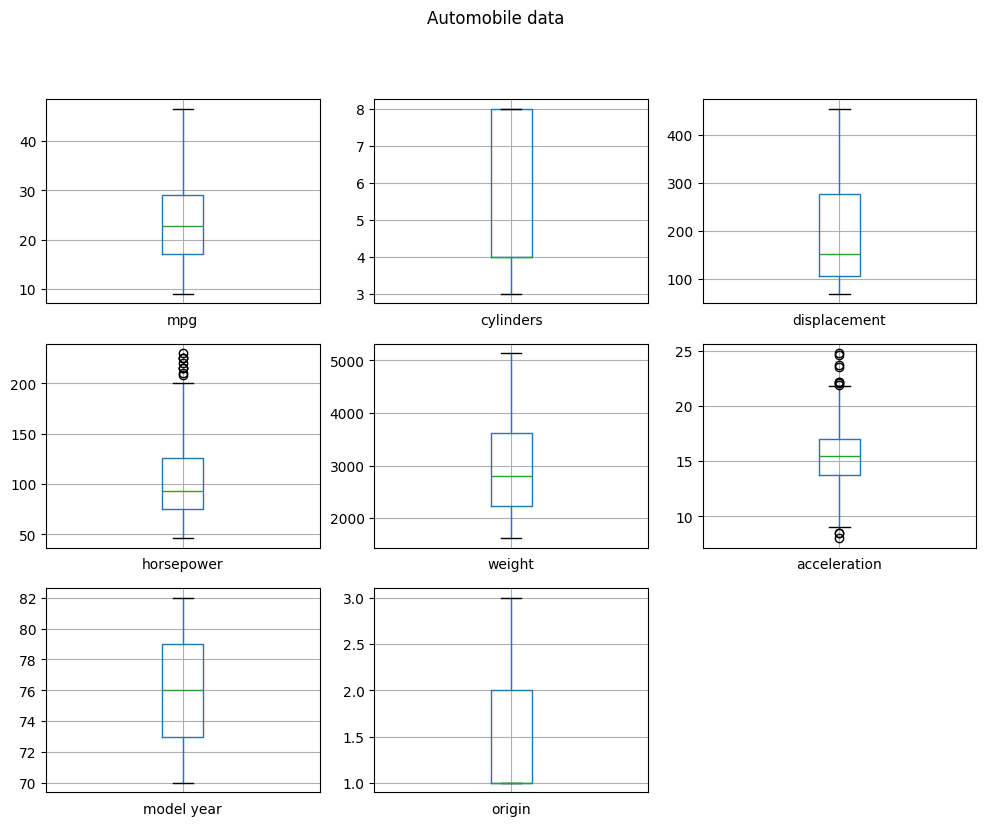

In [27]:
# compute layout
columns = auto_df.columns
plot_nums = len(columns)
plot_cols = 3
plot_rows = ((plot_nums-1)//plot_cols)+1
fig, subplots = plt.subplots(plot_rows, plot_cols, figsize = (12, 3*plot_rows))

# generate plots
for index, subplot in enumerate(subplots.flatten()):
  if index >= plot_nums:
    subplot.axis("off")
  else:
#    subplot.boxplot(auto_df[columns[index]])       # this doesn't plot for some columns
    auto_df[[columns[index]]].boxplot(ax=subplot)   # workaround for data that doesn't plot
    subplot.tick_params(
      axis='x',          # changes apply to the x-axis
      bottom=False,      # ticks along the bottom edge are off
    )
fig.suptitle("Automobile data") ;


#### Histograms

A loop to create a figure with subplots of histograms.

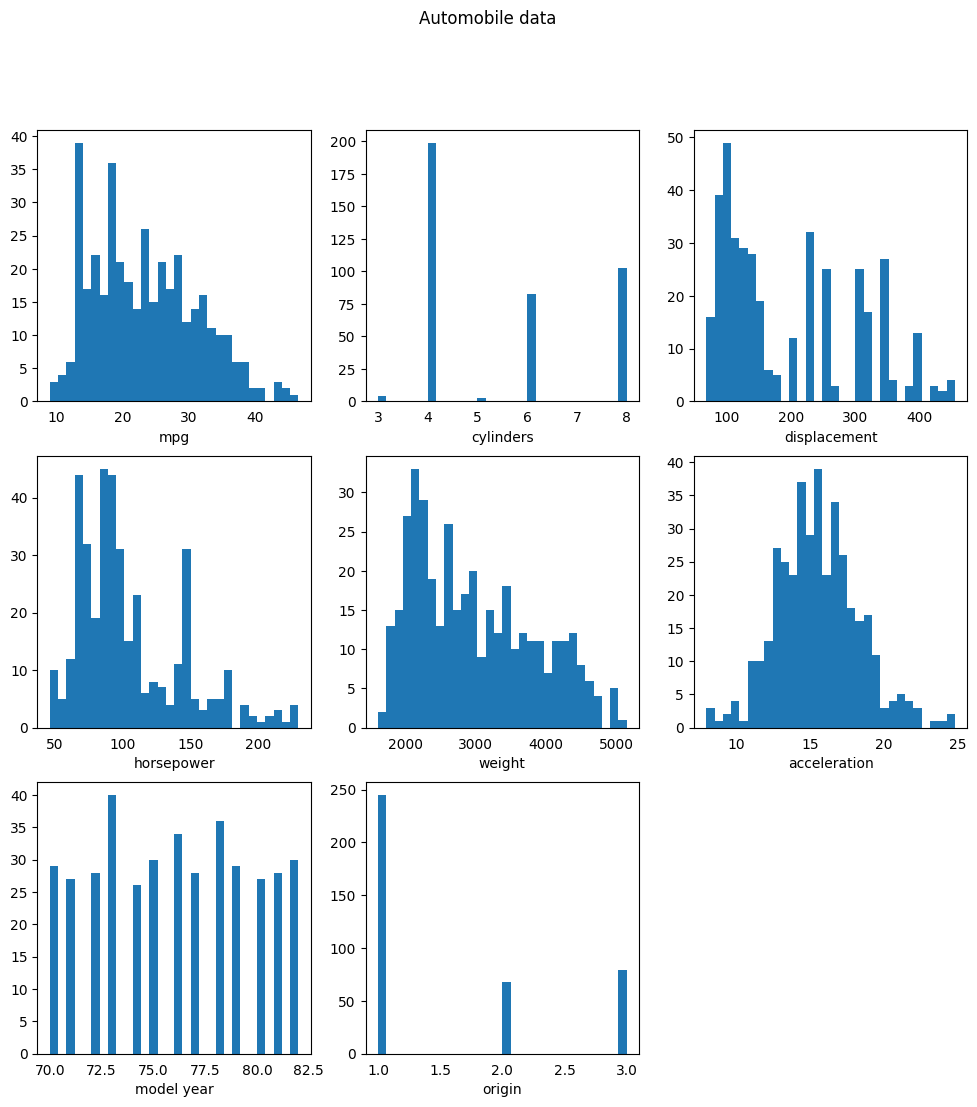

In [28]:
# compute layout
columns = auto_df.columns
plot_nums = len(columns)
plot_cols = 3
plot_rows = ((plot_nums-1)//plot_cols)+1
fig, subplots = plt.subplots(plot_rows, plot_cols, figsize = (12, 4*plot_rows))

# generate plots
for index, subplot in enumerate(subplots.flatten()):
  if index >= plot_nums:
    subplot.axis("off")
  else:
    subplot.hist(auto_df[columns[index]], bins=30)
#    auto_df[[columns[index]]].plot.hist(ax=subplot)   # alternative
    subplot.set_xlabel(columns[index])
    subplot.tick_params(
      axis='x',          # changes apply to the x-axis
      bottom=False,      # ticks along the bottom edge are off
    )
fig.suptitle("Automobile data") ;


#### Violins

A loop to create a figure with subplots of violin plots, a combination of histograms and box plots.

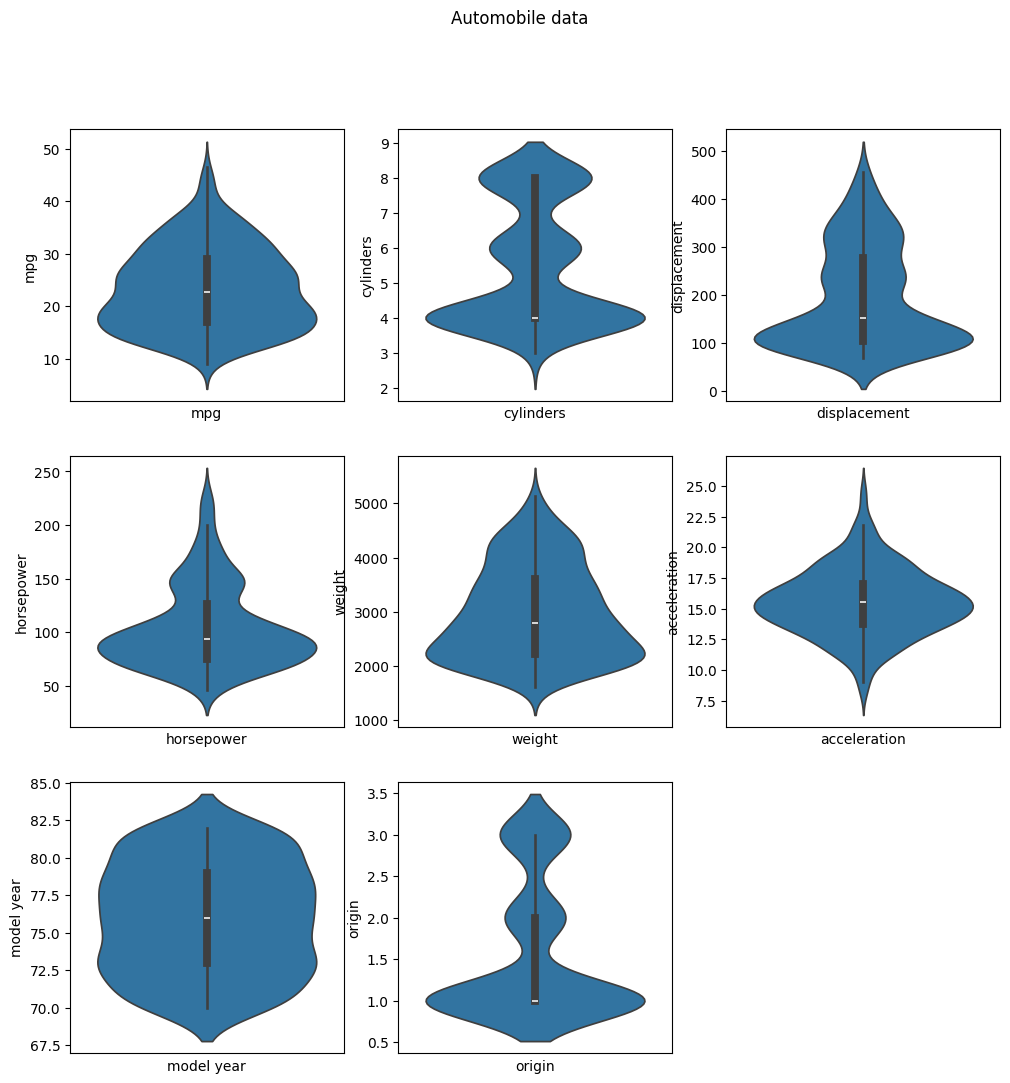

In [29]:
# compute layout
columns = auto_df.columns
plot_nums = len(columns)
plot_cols = 3
plot_rows = ((plot_nums-1)//plot_cols)+1
fig, subplots = plt.subplots(plot_rows, plot_cols, figsize = (12, 4*plot_rows))

# generate plots
for index, subplot in enumerate(subplots.flatten()):
  if index >= plot_nums:
    # don't plot anything for subplots without data
    subplot.axis("off")
  else:
    sns.violinplot(auto_df[columns[index]], ax=subplot)
    subplot.set_xlabel(columns[index])
    subplot.tick_params(
      axis='x',          # changes apply to the x-axis
      bottom=False,      # ticks along the bottom edge are off
      labelbottom=False,
    )
fig.suptitle("Automobile data") ;


Understanding the plotting model.

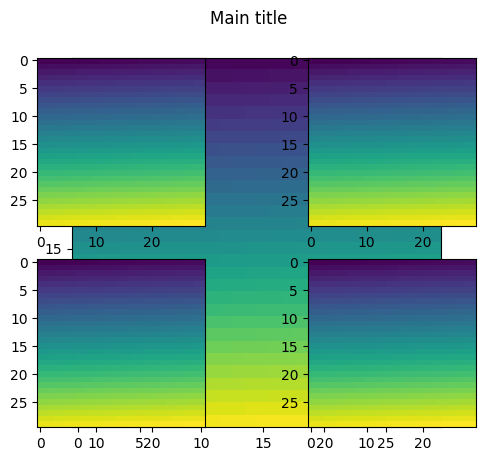

In [48]:
import numpy as np

data=np.arange(900).reshape((30,30))

fig=plt.figure()
# plot background plot
plt.imshow(data)

# plot quadrant plots
for i in range(1,5):
    subplot=fig.add_subplot(2,2,i)
    subplot.imshow(data)

fig.suptitle('Main title')
plt.show()

## Step 7: Bivariate plot (1/2)


Generate a correlation plot.


#### Calculate a correlation matrix

In [31]:
corr_matrix = auto_df.corr()
corr_matrix

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
mpg,1.000000,-0.777618,-0.805127,-0.778427,-0.832244,0.423329,0.580541,0.565209
cylinders,-0.777618,1.000000,0.950823,0.842983,0.897527,-0.504683,-0.345647,-0.568932
displacement,-0.805127,0.950823,1.000000,0.897257,0.932994,-0.543800,-0.369855,-0.614535
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361,-0.455171
weight,-0.832244,0.897527,0.932994,0.864538,1.000000,-0.416839,-0.309120,-0.585005
acceleration,0.423329,-0.504683,-0.543800,-0.689196,-0.416839,1.000000,0.290316,0.212746
model year,0.580541,-0.345647,-0.369855,-0.416361,-0.309120,0.290316,1.000000,0.181528
origin,0.565209,-0.568932,-0.614535,-0.455171,-0.585005,0.212746,0.181528,1.000000


Calculate a correlation matrix and round to two decimal places.


In [32]:
corr_matrix = auto_df.corr().round(2)
corr_matrix

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
mpg,1.00,-0.78,-0.81,-0.78,-0.83,0.42,0.58,0.57
cylinders,-0.78,1.00,0.95,0.84,0.90,-0.50,-0.35,-0.57
displacement,-0.81,0.95,1.00,0.90,0.93,-0.54,-0.37,-0.61
horsepower,-0.78,0.84,0.90,1.00,0.86,-0.69,-0.42,-0.46
weight,-0.83,0.90,0.93,0.86,1.00,-0.42,-0.31,-0.59
acceleration,0.42,-0.50,-0.54,-0.69,-0.42,1.00,0.29,0.21
model year,0.58,-0.35,-0.37,-0.42,-0.31,0.29,1.00,0.18
origin,0.57,-0.57,-0.61,-0.46,-0.59,0.21,0.18,1.00


Plot the correlation matrix as a heat map.

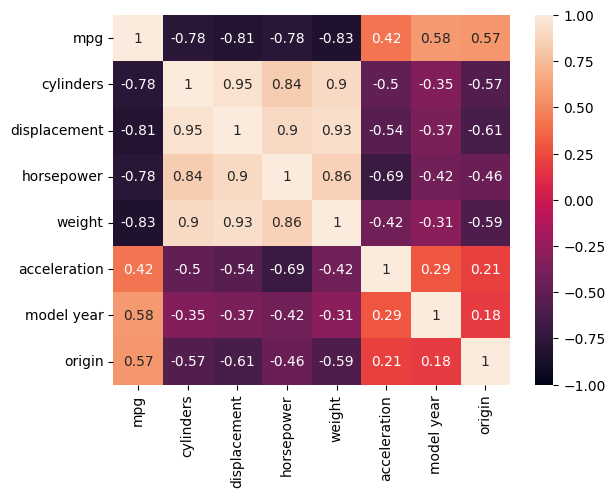

In [33]:
sns.heatmap(data=corr_matrix, annot=True, vmin=-1, vmax=1) ;

Notice a few features of the above heat map.
- the diagonal is 1, which is expected as it is a self correlation
- the top "triangle" of numbers is a mirror image of the bottom "triangle"
- a negative correlation is as meaningful as a positive correlation


#### List of correlations

In [34]:
corr_series = auto_df.corr().round(2).unstack()
corr_series

mpg     mpg             1.00
        cylinders      -0.78
        displacement   -0.81
        horsepower     -0.78
        weight         -0.83
                        ... 
origin  horsepower     -0.46
        weight         -0.59
        acceleration    0.21
        model year      0.18
        origin          1.00
Length: 64, dtype: float64

Since negative is as good as positive, let's take the absolute value of all numbers.

In [35]:
corrs = auto_df.corr().round(2).unstack().abs()
corrs


mpg     mpg             1.00
        cylinders       0.78
        displacement    0.81
        horsepower      0.78
        weight          0.83
                        ... 
origin  horsepower      0.46
        weight          0.59
        acceleration    0.21
        model year      0.18
        origin          1.00
Length: 64, dtype: float64

Filter out the self correlations, i.e. where the index names are the same

In [36]:
filter = corrs.index.get_level_values(0) != corrs.index.get_level_values(1)
filter.reshape(-1,8)

array([[False,  True,  True,  True,  True,  True,  True,  True],
       [ True, False,  True,  True,  True,  True,  True,  True],
       [ True,  True, False,  True,  True,  True,  True,  True],
       [ True,  True,  True, False,  True,  True,  True,  True],
       [ True,  True,  True,  True, False,  True,  True,  True],
       [ True,  True,  True,  True,  True, False,  True,  True],
       [ True,  True,  True,  True,  True,  True, False,  True],
       [ True,  True,  True,  True,  True,  True,  True, False]])

In [37]:
corrs_filtered = corrs[ filter ]
corrs_filtered


mpg           cylinders       0.78
              displacement    0.81
              horsepower      0.78
              weight          0.83
              acceleration    0.42
              model year      0.58
              origin          0.57
cylinders     mpg             0.78
              displacement    0.95
              horsepower      0.84
              weight          0.90
              acceleration    0.50
              model year      0.35
              origin          0.57
displacement  mpg             0.81
              cylinders       0.95
              horsepower      0.90
              weight          0.93
              acceleration    0.54
              model year      0.37
              origin          0.61
horsepower    mpg             0.78
              cylinders       0.84
              displacement    0.90
              weight          0.86
              acceleration    0.69
              model year      0.42
              origin          0.46
weight        mpg             0.83
              cylinders       0.90
              displacement    0.93
              horsepower      0.86
              acceleration    0.42
              model year      0.31
              origin          0.59
acceleration  mpg             0.42
              cylinders       0.50
              displacement    0.54
              horsepower      0.69
              weight          0.42
              model year      0.29
              origin          0.21
model year    mpg             0.58
              cylinders       0.35
              displacement    0.37
              horsepower      0.42
              weight          0.31
              acceleration    0.29
              origin          0.18
origin        mpg             0.57
              cylinders       0.57
              displacement    0.61
              horsepower      0.46
              weight          0.59
              acceleration    0.21
              model year      0.18
dtype: float64

Sort by correlation.

In [38]:
corrs_filtered.sort_values(ascending = False)


,,0
displacement,cylinders,0.95
cylinders,displacement,0.95
displacement,weight,0.93
weight,displacement,0.93
horsepower,displacement,0.90
displacement,horsepower,0.90
weight,cylinders,0.90
cylinders,weight,0.90
weight,horsepower,0.86
horsepower,weight,0.86


Notie that each correlation is duplicated, one from the top triangle and one from the bottom.  So, let's slice every other number.



In [39]:
corrs_filtered.sort_values(ascending = False)[::2]

displacement  cylinders       0.95
              weight          0.93
horsepower    displacement    0.90
weight        cylinders       0.90
              horsepower      0.86
cylinders     horsepower      0.84
mpg           weight          0.83
              displacement    0.81
              horsepower      0.78
cylinders     mpg             0.78
horsepower    acceleration    0.69
origin        displacement    0.61
              weight          0.59
model year    mpg             0.58
origin        mpg             0.57
mpg           origin          0.57
displacement  acceleration    0.54
acceleration  cylinders       0.50
origin        horsepower      0.46
mpg           acceleration    0.42
model year    horsepower      0.42
acceleration  mpg             0.42
model year    displacement    0.37
cylinders     model year      0.35
weight        model year      0.31
acceleration  model year      0.29
              origin          0.21
model year    origin          0.18
dtype: float64

> **Caveat**: notice that we lost cylinder:weight correlation by slicing.

#### Lower triangle of correlations

A more robust method would be to generate a list of the correlations from only the lower triangle.  Let's do that using masking.

Create a mask of all Trues of the same shape as the correlation matrix.

In [40]:
trues = np.full(corr_matrix.shape, True)
trues

array([[ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True,  True,  True,  True]])

Use the `np.triu()` method to create a matrix triangle. Triu is short for "triangle, upper".  There's a corresponding `np.tril()` for "triangle, lower".

In [41]:
np.triu?


In [42]:
triangle = np.triu(trues)
triangle

array([[ True,  True,  True,  True,  True,  True,  True,  True],
       [False,  True,  True,  True,  True,  True,  True,  True],
       [False, False,  True,  True,  True,  True,  True,  True],
       [False, False, False,  True,  True,  True,  True,  True],
       [False, False, False, False,  True,  True,  True,  True],
       [False, False, False, False, False,  True,  True,  True],
       [False, False, False, False, False, False,  True,  True],
       [False, False, False, False, False, False, False,  True]])

Notice that the upper triangle and the diagonal remain `True` while the lower triangle becomes `False`.  This may seem a bit backward, but for data frames the question is "do we want this element to be hidden?"  In this context, `False` means we want it to be shown.

If we apply the data frame mask to the data frame, we ony get the numbers for the lower triangle.

In [43]:
corr_matrix.mask(triangle)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
mpg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cylinders,-0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN
displacement,-0.81,0.95,NaN,NaN,NaN,NaN,NaN,NaN
horsepower,-0.78,0.84,0.90,NaN,NaN,NaN,NaN,NaN
weight,-0.83,0.90,0.93,0.86,NaN,NaN,NaN,NaN
acceleration,0.42,-0.50,-0.54,-0.69,-0.42,NaN,NaN,NaN
model year,0.58,-0.35,-0.37,-0.42,-0.31,0.29,NaN,NaN
origin,0.57,-0.57,-0.61,-0.46,-0.59,0.21,0.18,NaN


We can now create the series by appying the data frame mask, unstacking the data frame into a series, droping nulls, taking the absolute value, and sorting the series by value in descending order.

In [44]:
corr_series = (
  corr_matrix
  .mask(triangle)
  .unstack()
  .dropna()
  .abs()
  .sort_values(ascending = False)
)

corr_series.reset_index()

,level_0,level_1,0
0,cylinders,displacement,0.95
1,displacement,weight,0.93
2,displacement,horsepower,0.90
3,cylinders,weight,0.90
4,horsepower,weight,0.86
5,cylinders,horsepower,0.84
6,mpg,weight,0.83
7,mpg,displacement,0.81
8,mpg,horsepower,0.78
9,mpg,cylinders,0.78


All in one cell.

In [45]:
# create a matrix of True's with the same shape as the correlation matrix
# and apply the upper triangle

mask_np = np.triu(np.full(corr_matrix.shape, True))

# apply the numpy mask to the matrix, create a series, and clean it up
corr_series = (
  corr_matrix
  .mask(mask_np)
  .unstack()
  .dropna()
  .abs()
  .sort_values(ascending = False)
)
corr_series.reset_index()[:15]


,level_0,level_1,0
0,cylinders,displacement,0.95
1,displacement,weight,0.93
2,displacement,horsepower,0.90
3,cylinders,weight,0.90
4,horsepower,weight,0.86
5,cylinders,horsepower,0.84
6,mpg,weight,0.83
7,mpg,displacement,0.81
8,mpg,horsepower,0.78
9,mpg,cylinders,0.78


## Step 8: Bivariate plot (2/2)


Generate a pairplot.


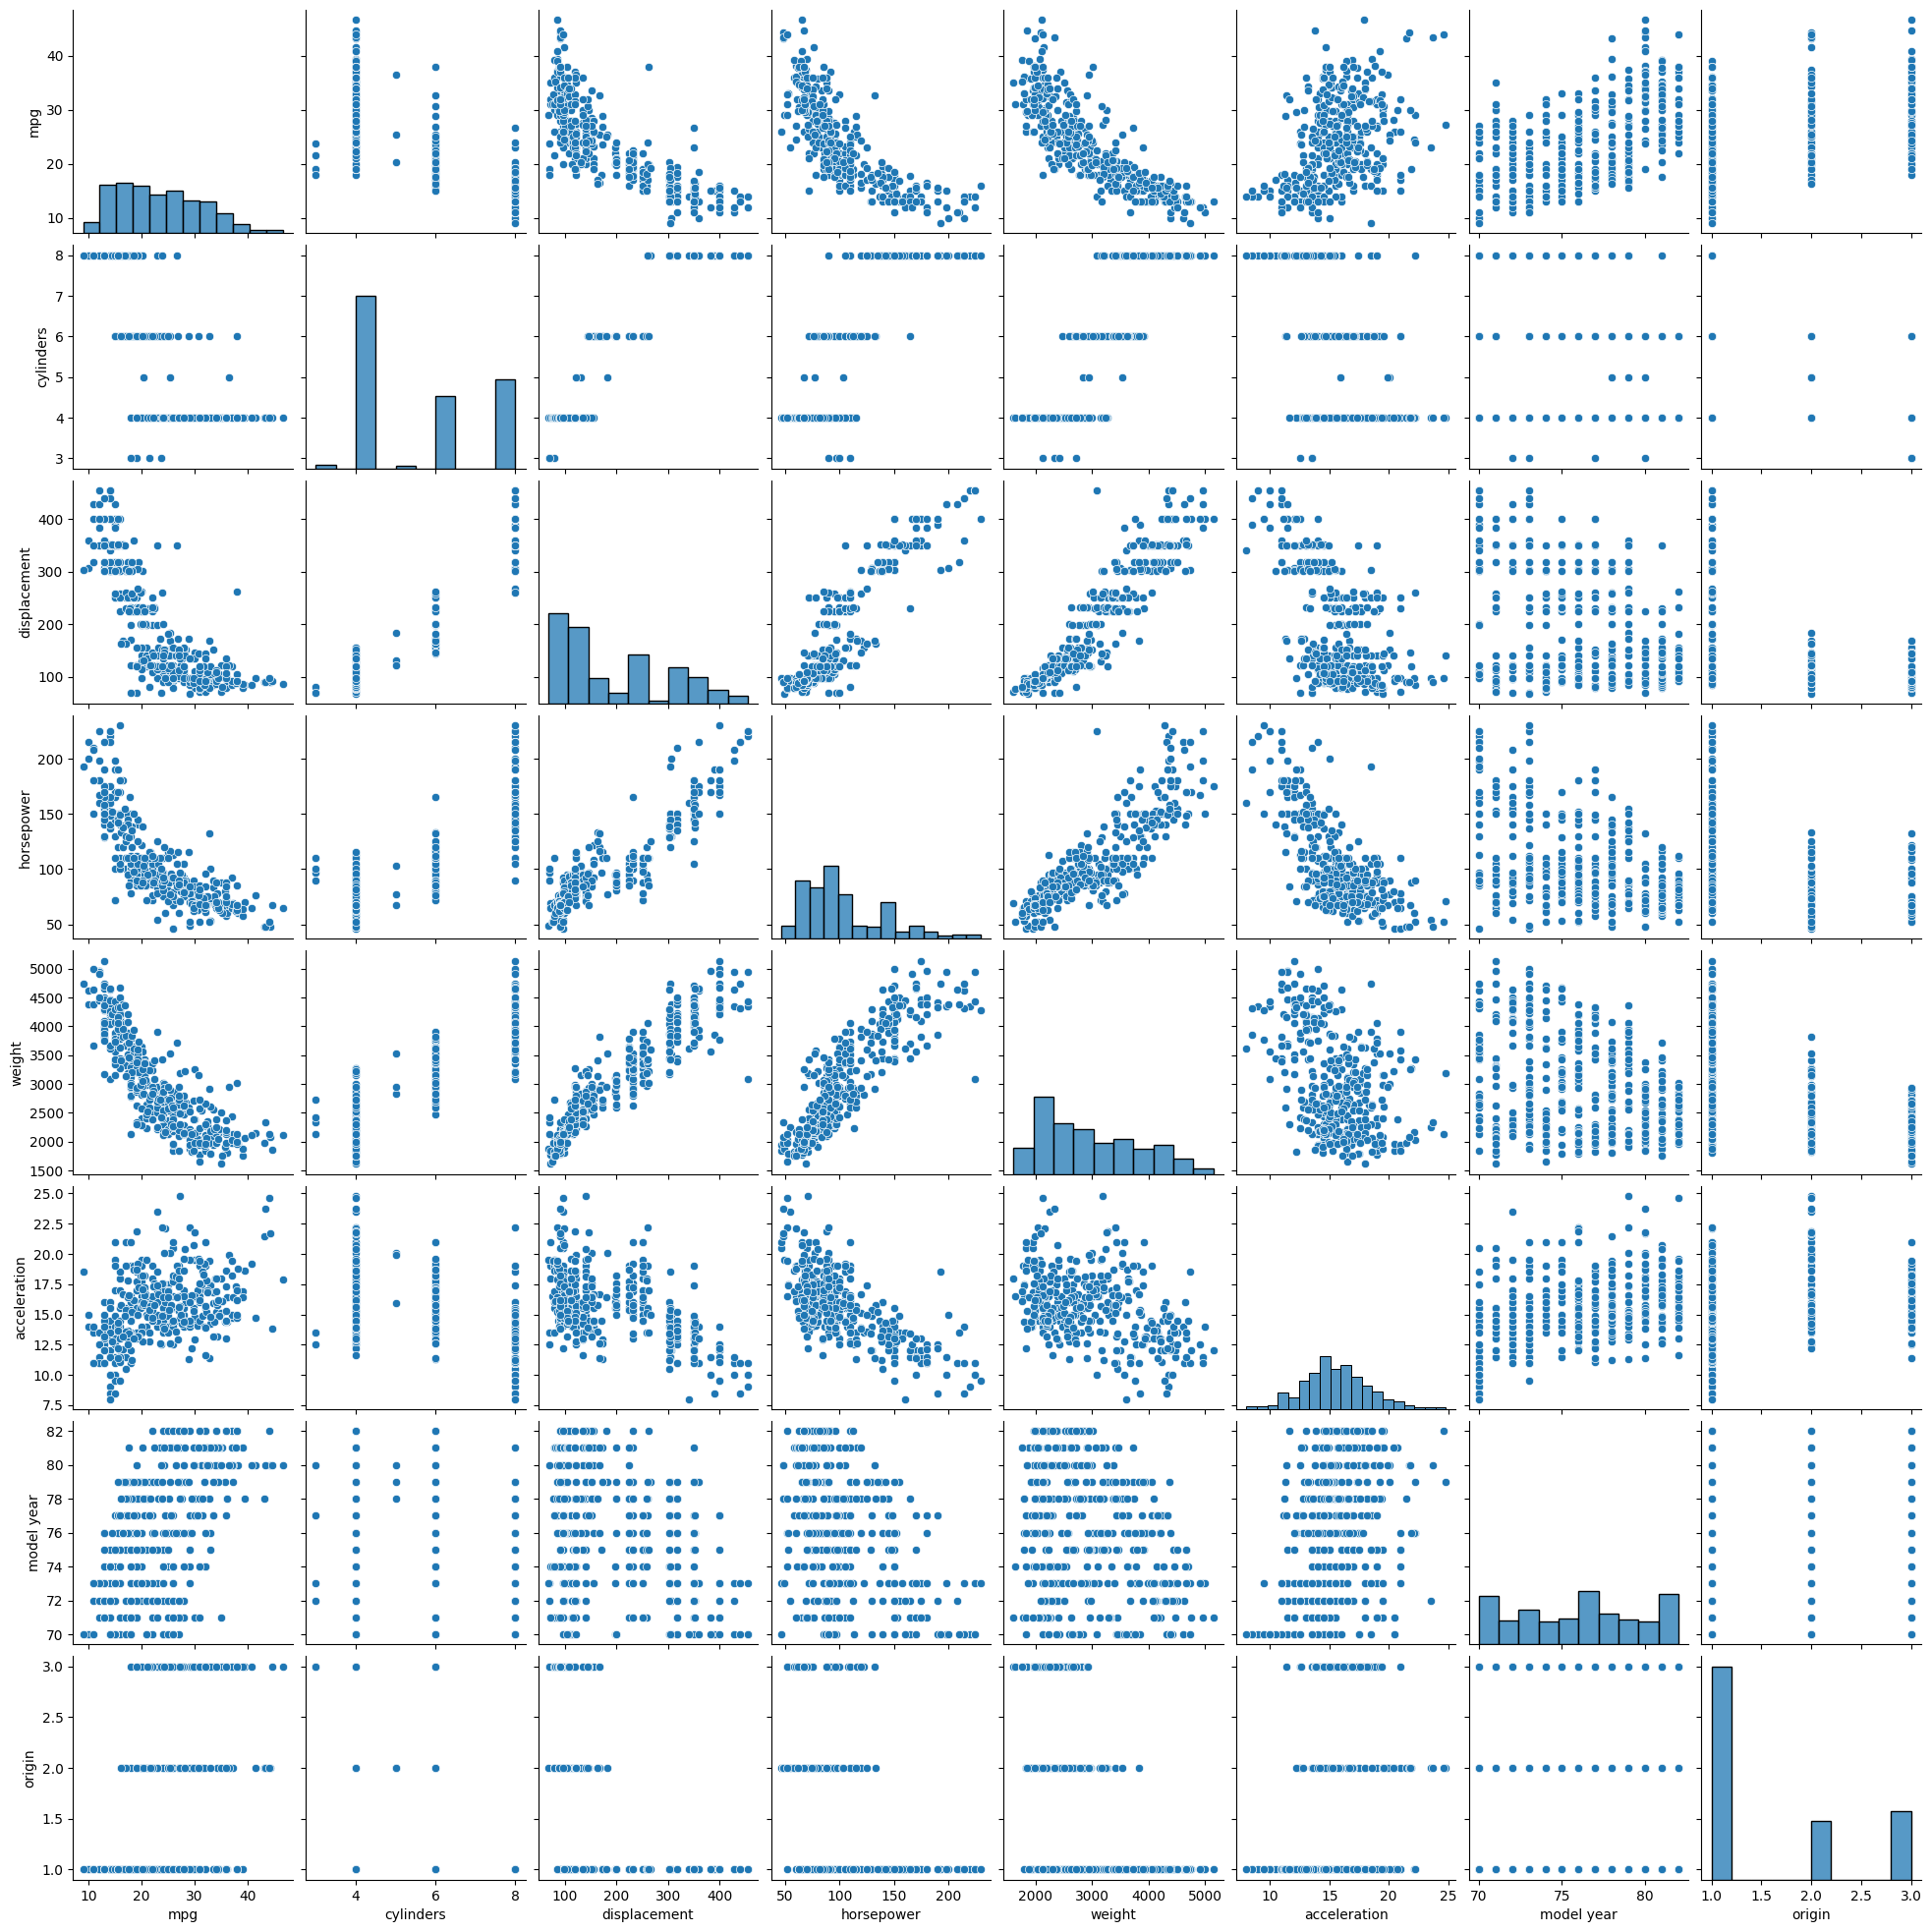

In [46]:
sns.pairplot(auto_df) ;

## Step 9: Conclusion


If we were going to build a predictive model ( supervised learning ) using this dataset, what do you think would be a good response ( aka target ) variable and why?

From the `.nunique()` results and the plots ( e.g. histogram and pairplot ) it becomes immediately obvious that these variables are categorical:

- origin
- cylinders
- model year

The remaining variables are continuous numerical variables.

Any variables with high correlation with other variables would be good response ( i.e. target ) variables as one set can be used to predict the response of the other.  Those would include these variables:

- weight
- displacement
- horsepower
- mpg
- acceleration

Two main characteristics of a response variable are these:

- difficult to measure directly, usually because of time or other resources.
- well correlated with features that are relatively easy to measure


Given the above characteristics, MPG and/or acceleration are what people will most likely want to know without having to measure them directly.

